# Global Superstore — quick EDA

Step 3 of the Data App group exercise: look at the data before deciding what belongs on the
dashboard. The file is `data/superstore.csv`, written by `prepare_data.py`.

**What one row is:** one line of one order (product × quantity × discount). An order with three
different products is three rows.

**Where it comes from:** the Global Superstore sample, the classic Tableau/Power-BI retail dataset that
is also distributed on Kaggle as *Global Superstore Data*. It is a **synthetic** sample, not a real
company's books — declared here because that matters when reading the numbers.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8')
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

df = pd.read_csv('data/superstore.csv', parse_dates=['Order Date', 'Ship Date'])
print(f'{len(df):,} order lines x {df.shape[1]} columns')
print(f'{df["Order ID"].nunique():,} orders, {df["Customer ID"].nunique():,} customers')
print(f'{df["Order Date"].min().date()} to {df["Order Date"].max().date()}')
df.head()

51,290 order lines x 28 columns
25,035 orders, 1,590 customers
2011-01-01 to 2014-12-31


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority,Returned,Order Year,Order Month,Lead Days
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,"2,309.65",7,0.00,762.18,933.57,Critical,False,2012,2012-07,0
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,"3,709.39",9,0.10,-288.76,923.63,Critical,True,2013,2013-02,2
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,"5,175.17",9,0.10,919.97,915.49,Medium,False,2013,2013-10,1
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,"2,892.51",5,0.10,-96.54,910.16,Medium,False,2013,2013-01,2
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,"2,832.96",8,0.00,311.52,903.04,Critical,False,2013,2013-11,1


## 1. Shape, types, and what is missing

Nearly everything is complete. The one exception is **Postal Code, missing for 80% of the rows** —
worth remembering, because any "sales by postcode" view would be built on the fifth of the data that
has one.

In [2]:
missing = df.isna().sum()
missing = missing[missing > 0]
print('Columns with missing values:')
print((pd.DataFrame({'missing': missing, 'share %': (missing / len(df) * 100).round(1)})
       .sort_values('missing', ascending=False)).to_string())

print('\nData types:')
print(df.dtypes.value_counts().to_string())

Columns with missing values:
             missing  share %
Postal Code    41296    80.50

Data types:
str               16
float64            5
int64              4
datetime64[us]     2
bool               1


## 2. Volume over time

48 complete months, 2011 through 2014. Revenue grows steadily — which is exactly the kind of chart that
makes a business look healthy, and the reason the dashboard must not stop there.

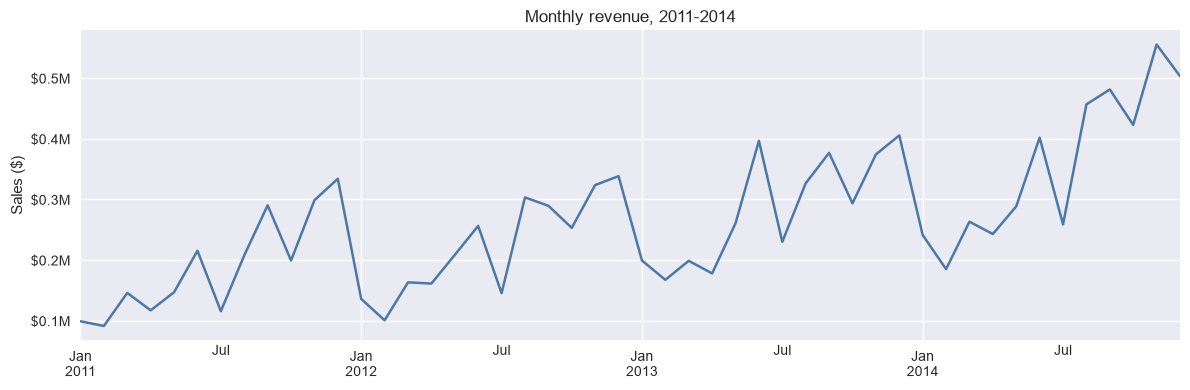

                  sales     profit  margin %  avg discount
Order Date                                                
2011       2,259,451.00 248,941.00     11.00          0.00
2012       2,677,439.00 307,415.00     11.00          0.00
2013       3,405,746.00 406,935.00     12.00          0.00
2014       4,299,866.00 504,166.00     12.00          0.00


In [3]:
monthly = df.groupby(df['Order Date'].dt.to_period('M')).agg(sales=('Sales', 'sum'), profit=('Profit', 'sum'))
monthly['margin %'] = monthly.profit / monthly.sales * 100

fig, ax = plt.subplots(figsize=(12, 4))
monthly.sales.plot(ax=ax, color='#4C78A8', lw=1.8)
ax.set_title('Monthly revenue, 2011-2014')
ax.set_ylabel('Sales ($)')
ax.set_xlabel('')
ax.yaxis.set_major_formatter(lambda v, p: f'${v / 1e6:.1f}M')
plt.tight_layout()
plt.show()

yearly = df.groupby(df['Order Date'].dt.year).agg(sales=('Sales', 'sum'), profit=('Profit', 'sum'))
yearly['margin %'] = (yearly.profit / yearly.sales * 100).round(2)
yearly['avg discount'] = df.groupby(df['Order Date'].dt.year).Discount.mean().round(3)
print(yearly.round(0).to_string())

## 3. The discount distribution is not a distribution at all

Discount is bimodal: more than half of all order lines are sold at **full price**, and a second big
cluster sits at **20% and above**. That single fact decides what the dashboard's main chart has to be —
an "average discount" number would hide it completely.

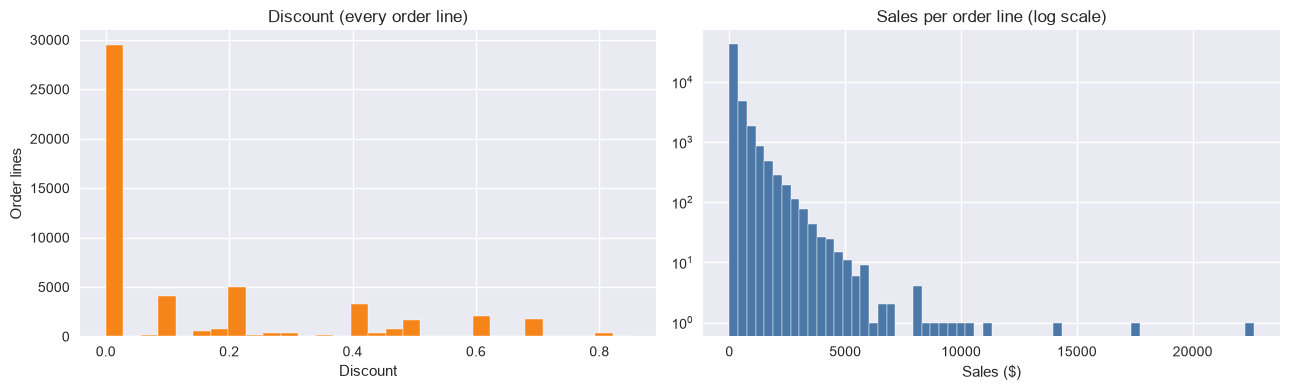

Lines at exactly 0% discount : 56.6%
Lines at 20% or more          : 31.8%
Mean discount                 : 14.3%  <- averages two populations, means little


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
df.Discount.hist(bins=30, ax=ax1, color='#F58518', edgecolor='white')
ax1.set_title('Discount (every order line)')
ax1.set_xlabel('Discount')
ax1.set_ylabel('Order lines')

df.Sales.hist(bins=60, ax=ax2, color='#4C78A8', edgecolor='white')
ax2.set_yscale('log')
ax2.set_title('Sales per order line (log scale)')
ax2.set_xlabel('Sales ($)')
plt.tight_layout()
plt.show()

print(f'Lines at exactly 0% discount : {(df.Discount == 0).mean() * 100:.1f}%')
print(f'Lines at 20% or more          : {(df.Discount >= 0.2).mean() * 100:.1f}%')
print(f'Mean discount                 : {df.Discount.mean() * 100:.1f}%  <- averages two populations, means little')

## 4. Discount is where the margin goes

This is the finding the dashboard is built on. Full-price lines return **+25%**. Past 20% the margin
turns negative, and of the 10,361 lines sold at more than 30% off, **92.5% lost money**. Those lines are
12% of revenue and **-51% margin**.

               lines        sales       profit  margin %  loss-making lines %  share of sales %
Discount                                                                                       
0%             29009 6,992,411.00 1,770,695.30     25.30                 0.00             55.30
1-10%           4679 1,962,618.80   338,189.30     17.20                19.30             15.50
11-20%          6274 1,757,261.30   173,254.80      9.90                23.30             13.90
21-30%           967   382,554.70   -21,155.60     -5.50                62.20              3.00
more than 30%  10361 1,547,656.10  -793,526.50    -51.30                92.50             12.20


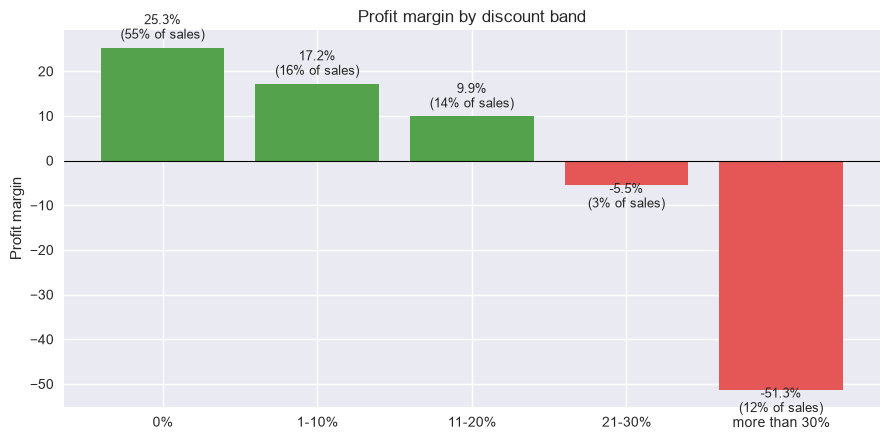

In [5]:
bands = pd.cut(df.Discount, [-0.001, 0, 0.1, 0.2, 0.3, 1.0],
               labels=['0%', '1-10%', '11-20%', '21-30%', 'more than 30%'])
by_band = df.groupby(bands, observed=True).agg(lines=('Profit', 'size'), sales=('Sales', 'sum'),
                                               profit=('Profit', 'sum'))
by_band['margin %'] = (by_band.profit / by_band.sales * 100).round(1)
by_band['loss-making lines %'] = df.assign(neg=df.Profit < 0).groupby(bands, observed=True)['neg'].mean().mul(100).round(1)
by_band['share of sales %'] = (by_band.sales / df.Sales.sum() * 100).round(1)
print(by_band.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#54A24B' if m > 0 else '#E45756' for m in by_band['margin %']]
bars = ax.bar(by_band.index.astype(str), by_band['margin %'], color=colors)
ax.axhline(0, color='black', lw=0.8)
for b, m, s in zip(bars, by_band['margin %'], by_band['share of sales %']):
    ax.text(b.get_x() + b.get_width() / 2, m + (2 if m > 0 else -5), f'{m:.1f}%\n({s:.0f}% of sales)',
            ha='center', fontsize=9)
ax.set_title('Profit margin by discount band')
ax.set_ylabel('Profit margin')
plt.tight_layout()
plt.show()

## 5. Where it happens: region and product

Inside the US market the four regions differ sharply — and the differences line up with how deeply they
discount. Central sells at 28% off on nearly a third of its lines and returns 7.9%; West discounts far
less and returns 14.9%.

At product level, **Tables** is the single loss-maker: -$64,083 at an average 29% discount.

         orders      sales     profit  margin %  avg discount  loss-making lines %  lines at 30%+ off %
Region                                                                                                 
Central    1175 501,239.89  39,706.36      7.90          0.24                31.90                27.70
South       822 391,721.91  46,749.43     11.90          0.15                16.00                10.60
East       1401 678,781.24  91,522.78     13.50          0.14                19.40                16.20
West       1611 725,457.82 108,418.45     14.90          0.11                 9.90                 3.70


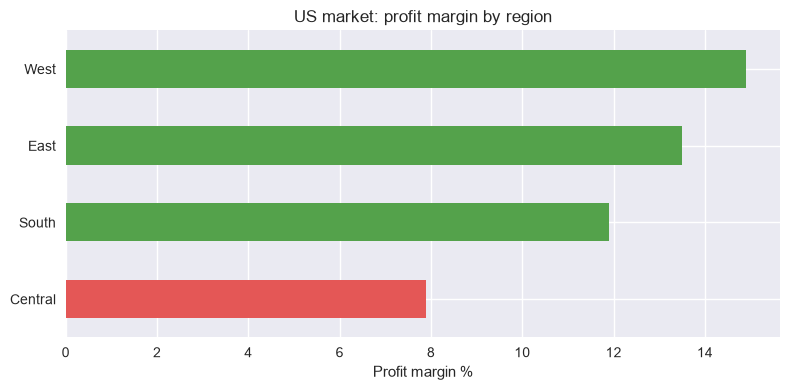

In [6]:
us = df[df.Market == 'US']
region = us.groupby('Region').agg(orders=('Order ID', 'nunique'), sales=('Sales', 'sum'), profit=('Profit', 'sum'))
region['margin %'] = (region.profit / region.sales * 100).round(1)
region['avg discount'] = us.groupby('Region').Discount.mean().round(3)
region['loss-making lines %'] = us.assign(n=us.Profit < 0).groupby('Region')['n'].mean().mul(100).round(1)
region['lines at 30%+ off %'] = us.assign(d=us.Discount >= 0.3).groupby('Region')['d'].mean().mul(100).round(1)
print(region.sort_values('margin %').to_string())

fig, ax = plt.subplots(figsize=(8, 4))
region.sort_values('margin %')['margin %'].plot.barh(ax=ax, color=['#E45756' if m < 10 else '#54A24B' for m in region.sort_values('margin %')['margin %']])
ax.set_title('US market: profit margin by region')
ax.set_xlabel('Profit margin %')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

                    sales     profit  avg_discount  lines  margin %
Sub-Category                                                       
Tables         757,041.92 -64,083.39          0.29    861     -8.50
Machines       779,060.07  58,867.87          0.17   1486      7.60
Chairs       1,501,681.76 140,396.27          0.16   3434      9.30
Supplies       243,074.22  22,583.26          0.13   2425      9.30
Storage      1,127,085.86 108,461.49          0.14   5059      9.60
Bookcases    1,466,572.24 161,924.42          0.15   2411     11.00
Furnishings    385,578.26  46,967.43          0.15   3170     12.20
Phones       1,706,824.14 216,717.01          0.15   3357     12.70
Fasteners       83,242.32  11,525.42          0.14   2420     13.80
Appliances   1,011,064.30 141,680.59          0.14   1755     14.00
Art            372,091.97  57,953.91          0.12   4883     15.60
Binders        461,911.51  72,449.85          0.18   6152     15.70
Copiers      1,509,436.27 258,567.55          0.

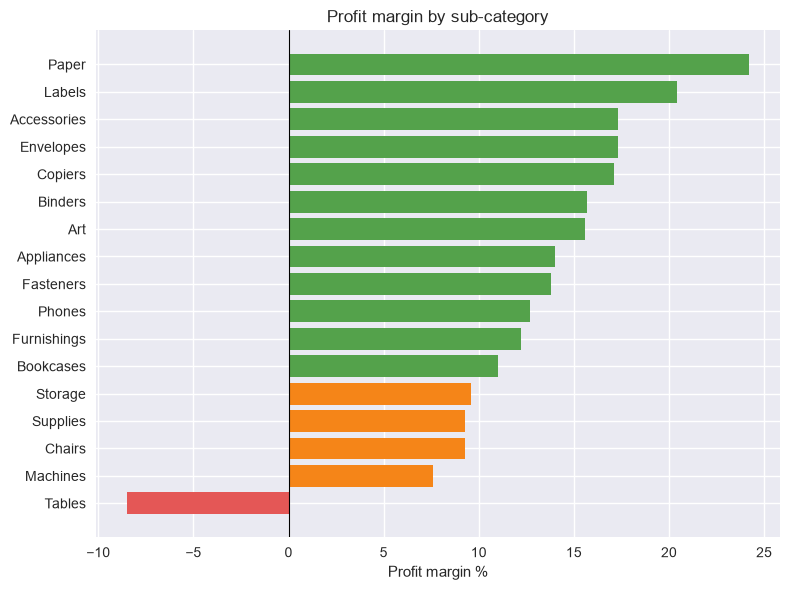

In [7]:
sub = df.groupby('Sub-Category').agg(sales=('Sales', 'sum'), profit=('Profit', 'sum'),
                                     avg_discount=('Discount', 'mean'), lines=('Profit', 'size'))
sub['margin %'] = (sub.profit / sub.sales * 100).round(1)
sub = sub.sort_values('margin %')
print(sub.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#E45756' if m < 0 else ('#F58518' if m < 10 else '#54A24B') for m in sub['margin %']]
ax.barh(sub.index, sub['margin %'], color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Profit margin by sub-category')
ax.set_xlabel('Profit margin %')
plt.tight_layout()
plt.show()

## 6. Returns

1,172 of the 25,035 orders were returned — **4.7%**. Returns are stored as a flag on the order, not as a
negative row, so every revenue figure above is **gross of returns**. The dashboard says so in a caption
rather than pretending the number is net.

In [8]:
order_level = df.groupby('Order ID').agg(returned=('Returned', 'first'), sales=('Sales', 'sum'))
print(f'Order-level return rate: {order_level.returned.mean() * 100:.2f}%')
print(f'Sales on returned orders: ${order_level.loc[order_level.returned, "sales"].sum():,.0f} '
      f'({order_level.loc[order_level.returned, "sales"].sum() / order_level.sales.sum() * 100:.1f}% of gross)')
print()
print('By category:')
print(df.groupby('Category').Returned.mean().mul(100).round(2).to_string())

Order-level return rate: 4.68%
Sales on returned orders: $819,020 (6.5% of gross)

By category:
Category
Furniture         6.46
Office Supplies   5.72
Technology        6.15


## What this EDA decides

**On the dashboard**

1. **Margin**, not revenue, is the headline. Revenue grew every year and says nothing about health; the
   24.5% of order lines that lose money do.
2. **The discount chart is the one supporting chart that earns its place** — it is the mechanism behind
   the margin number, and it points at a lever the director can actually pull.
3. **Region is the only filter.** The director owns four of them and nothing else.

**Off the dashboard**

- A world map of sales by country: pretty, unactionable, and built on country names that are not
  standardised. It would not change a single discount decision.
- A top-10 customers table: 1,590 customers, and a leaderboard invites one-off exceptions instead of the
  policy change the decision needs.

**What could mislead the reader**

- Revenue is gross of returns (4.7% of orders come back).
- "Average discount" is meaningless here: the data is bimodal.
- A loss-making *share* counts a -$3 line the same as a -$30,000 one, so the loss is always shown in
  dollars next to it.
- Postal Code is missing for 4 in 5 rows.